# 03. Предобработка данных

**Вход:** `data/flats.csv` — витрина из `02_sql.ipynb` (продажа и аренда, Астана).
**Выход:** `data/clean_flats.pkl` / `.csv` для этапов 4–7.

Что делаем:
1. Фиксируем исходный объём (сырые объявления → витрина после SQL-фильтров).
2. Дубли: по id и «по смыслу» — одна квартира, выставленная несколькими риелторами.
3. Логические проверки: этаж больше этажности, слишком маленькая площадь на комнату.
4. Выбросы цены за м² — отдельно для продажи и аренды.
5. Пропуски и типы данных.
6. Новые признаки для анализа.
7. Итог «До и После».

In [2]:
import glob
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DATA = Path("data")
raw = pd.read_csv(sorted(glob.glob("data/raw/listings_*.csv"))[-1])
df = pd.read_csv(DATA / "flats.csv")

log = []  # журнал очистки
def step(name, before, after, reason):
    log.append({"шаг": name, "было": before, "стало": after, "удалено": before - after, "причина": reason})
    print(f"{name}: {before} → {after} (−{before - after})")

N_RAW = len(raw)
step("SQL-фильтры (v_flats)", N_RAW, len(df),
     "площадь вне 12–400 м², аренда дешевле 50 тыс. ₸ (посуточная), продажа дешевле 5 млн ₸")
print()
print(df.groupby("deal").size())
df.info()

SQL-фильтры (v_flats): 5755 → 5749 (−6)

deal
rent    2809
sale    2940
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5749 entries, 0 to 5748
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   listing_id       5749 non-null   int64  
 1   deal             5749 non-null   object 
 2   district         5749 non-null   object 
 3   bank             5749 non-null   object 
 4   rooms_grp        5749 non-null   int64  
 5   rooms            5749 non-null   int64  
 6   area_m2          5749 non-null   float64
 7   floor            5294 non-null   float64
 8   floors_total     5040 non-null   float64
 9   floor_type       5749 non-null   object 
 10  building_height  5040 non-null   object 
 11  price_kzt        5749 non-null   int64  
 12  price_per_m2     5749 non-null   float64
dtypes: float64(4), int64(4), object(5)
memory usage: 584.0+ KB


## 1. Дубликаты

In [3]:
before = len(df)
df = df.drop_duplicates(subset="listing_id")
step("Дубли по id", before, len(df), "одно и то же объявление")

# Одна квартира от нескольких риелторов: совпадают тип сделки, район, комнаты, площадь, этажи и цена
KEY = ["deal", "district", "rooms", "area_m2", "floor", "floors_total", "price_kzt"]
dup_mask = df.duplicated(subset=KEY, keep=False)
print(f"\nПовторно выставленных квартир: {df.duplicated(subset=KEY).sum()}")
display(df[dup_mask].sort_values(KEY)[["listing_id"] + KEY].head(8))

before = len(df)
df = df.drop_duplicates(subset=KEY, keep="first")
step("Повторные размещения", before, len(df), "одна квартира выставлена несколькими риелторами")

Дубли по id: 5749 → 5749 (−0)

Повторно выставленных квартир: 72


,listing_id,deal,district,rooms,area_m2,floor,floors_total,price_kzt
3391,1017040911,rent,Алматинский,1,22.0,NaN,NaN,400000
3394,1015980429,rent,Алматинский,1,22.0,NaN,NaN,400000
3663,1008930327,rent,Алматинский,1,36.0,4.0,5.0,270000
4019,1005098783,rent,Алматинский,1,36.0,4.0,5.0,270000
4646,1014972644,rent,Алматинский,1,36.0,4.0,5.0,270000
3221,54097481,rent,Алматинский,2,60.0,3.0,5.0,240000
3444,1012686172,rent,Алматинский,2,60.0,3.0,5.0,240000
2979,1017123671,rent,Алматинский,3,86.0,9.0,9.0,350000


Повторные размещения: 5749 → 5677 (−72)


## 2. Логические проверки

In [4]:
bad_floor = df["floor"] > df["floors_total"]
df["m2_per_room"] = df["area_m2"] / df["rooms"]
tiny = df["m2_per_room"] < 10

print(f"Этаж больше этажности дома: {bad_floor.sum()}")
print(f"Меньше 10 м² на комнату: {tiny.sum()}")
print(f"Больше 70 м² на комнату: {(df['m2_per_room'] > 70).sum()} (оставляем — бывают квартиры-студии свободной планировки)")

before = len(df)
df = df[~bad_floor & ~tiny]
step("Логические ошибки", before, len(df), "этаж выше этажности или нереальная площадь на комнату")

Этаж больше этажности дома: 0
Меньше 10 м² на комнату: 0
Больше 70 м² на комнату: 2 (оставляем — бывают квартиры-студии свободной планировки)
Логические ошибки: 5677 → 5677 (−0)


## 3. Выбросы цены за м²

Цена за м² распределена несимметрично, поэтому границы считаем по IQR на **логарифме**
и отдельно для продажи и аренды. За границами — элитные пентхаусы, ошибки ввода
и «комнаты в квартире», выставленные как квартиры. Они не относятся к бюджету клиентов агентства
и искажают медианы сегментов.

rent: норма 2 993 – 11 013 ₸ за м²
sale: норма 287 625 – 1 451 530 ₸ за м²

Выбросов: 97


deal
rent    84
sale    13
dtype: int64

,deal,district,rooms,area_m2,price_kzt,price_per_m2
4092,rent,Алматинский,5,360.0,600000,1667.0
4059,rent,Не указан,3,90.0,155000,1722.0
4562,rent,Нура,2,60.0,105000,1750.0
3875,rent,Сарайшык,4,156.0,350000,2244.0
5185,rent,Сарыарка,2,52.0,120000,2308.0
5386,rent,Алматинский,3,145.0,350000,2414.0
5322,rent,Байконур,4,100.0,250000,2500.0
5673,rent,Не указан,3,136.0,350000,2574.0
3521,rent,Сарайшык,2,76.0,200000,2632.0
4342,rent,Есильский,3,130.0,350000,2692.0


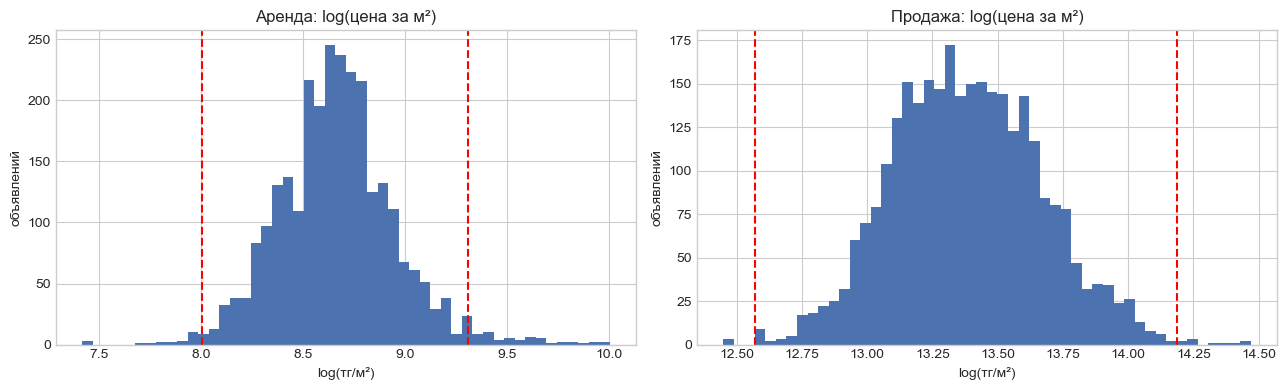

In [5]:
def iqr_bounds(s, k=1.5):
    x = np.log(s)
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return np.exp(q1 - k * iqr), np.exp(q3 + k * iqr)

bounds = {d: iqr_bounds(g["price_per_m2"]) for d, g in df.groupby("deal")}
for d, (lo, hi) in bounds.items():
    print(f"{d}: норма {lo:,.0f} – {hi:,.0f} ₸ за м²".replace(",", " "))

df["is_outlier"] = df.apply(
    lambda r: not (bounds[r["deal"]][0] <= r["price_per_m2"] <= bounds[r["deal"]][1]), axis=1
)
print(f"\nВыбросов: {df['is_outlier'].sum()}")
display(df[df["is_outlier"]].groupby("deal").size())
display(df[df["is_outlier"]].sort_values("price_per_m2")[["deal", "district", "rooms", "area_m2", "price_kzt", "price_per_m2"]].head(10))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (d, g) in zip(axes, df.groupby("deal")):
    ax.hist(np.log(g["price_per_m2"]), bins=50, color="#4C72B0")
    lo, hi = bounds[d]
    ax.axvline(np.log(lo), color="red", ls="--"); ax.axvline(np.log(hi), color="red", ls="--")
    ax.set(title=f"{'Продажа' if d == 'sale' else 'Аренда'}: log(цена за м²)", xlabel="log(тг/м²)", ylabel="объявлений")
plt.tight_layout(); plt.show()

In [6]:
before = len(df)
df = df[~df["is_outlier"]].drop(columns="is_outlier")
step("Выбросы цены за м²", before, len(df), "за границами 1.5 IQR на логарифме (пентхаусы, ошибки ввода)")

Выбросы цены за м²: 5677 → 5580 (−97)


## 4. Пропуски и типы данных

In [7]:
print("Пропуски:")
display(df.isna().sum()[lambda s: s > 0])

Пропуски:


floor              431
floors_total       678
building_height    678
dtype: int64

- **Этаж / этажность** не указаны в части заголовков объявлений. Числами **не заполняем**:
  придуманный этаж исказил бы гипотезу H3. Для таких объявлений тип этажа — «Не указан»,
  а в H3 и регрессию они не попадают.
- **Район** не определён у ≈2% объявлений (адрес без района). Оставляем для общегородских
  показателей, но не используем в сравнениях по районам и берегам.

In [8]:
df["building_height"] = df["building_height"].fillna("Не указан")
df["floor"] = df["floor"].astype("Int64")
df["floors_total"] = df["floors_total"].astype("Int64")

for col in ["deal", "district", "bank", "floor_type", "building_height"]:
    df[col] = df[col].astype("category")
df["rooms_grp"] = pd.Categorical(df["rooms_grp"], categories=[1, 2, 3, 4], ordered=True)

df.dtypes

listing_id            int64
deal               category
district           category
bank               category
rooms_grp          category
rooms                 int64
area_m2             float64
floor                 Int64
floors_total          Int64
floor_type         category
building_height    category
price_kzt             int64
price_per_m2        float64
m2_per_room         float64
dtype: object

## 5. Новые признаки

In [9]:
df["price_mln"] = (df["price_kzt"] / 1e6).round(2)
df["is_edge_floor"] = df["floor_type"].isin(["Первый", "Последний"])
df["has_district"] = df["district"] != "Не указан"
df["area_grp"] = pd.cut(df["area_m2"], bins=[0, 40, 60, 80, 120, 400],
                        labels=["до 40", "40–60", "60–80", "80–120", "120+"])
df["in_client_budget"] = (df["deal"] == "sale") & df["price_kzt"].between(20e6, 50e6)

print(f"Квартир на продажу в бюджете клиентов (20–50 млн ₸): "
      f"{df['in_client_budget'].sum()} из {(df['deal'] == 'sale').sum()} "
      f"({df['in_client_budget'].sum() / (df['deal'] == 'sale').sum():.0%})")

Квартир на продажу в бюджете клиентов (20–50 млн ₸): 1799 из 2922 (62%)


## 6. Итог: «До и После»

In [10]:
summary = pd.DataFrame(log)
display(summary)

after = df.groupby("deal", observed=True).size()
before_raw = raw.groupby("deal").size()
print(f"Всего: {N_RAW} → {len(df)} (потеряно {1 - len(df) / N_RAW:.1%})")
for d in ["sale", "rent"]:
    print(f"  {d}: {before_raw[d]} → {after[d]} (потеряно {1 - after[d] / before_raw[d]:.1%})")

,шаг,было,стало,удалено,причина
0,SQL-фильтры (v_flats),5755,5749,6,"площадь вне 12–400 м², аренда дешевле 50 тыс. ..."
1,Дубли по id,5749,5749,0,одно и то же объявление
2,Повторные размещения,5749,5677,72,одна квартира выставлена несколькими риелторами
3,Логические ошибки,5677,5677,0,этаж выше этажности или нереальная площадь на ...
4,Выбросы цены за м²,5677,5580,97,"за границами 1.5 IQR на логарифме (пентхаусы, ..."


Всего: 5755 → 5580 (потеряно 3.0%)
  sale: 2941 → 2922 (потеряно 0.6%)
  rent: 2814 → 2658 (потеряно 5.5%)


Потеряно менее 5% объявлений — данные изначально довольно чистые. Больше всего удалено
повторных размещений в аренде (одну квартиру сдают через нескольких риелторов) и выбросов
цены за м² в аренде.

In [11]:
df.to_pickle(DATA / "clean_flats.pkl")
df.to_csv(DATA / "clean_flats.csv", index=False, encoding="utf-8-sig")
print(f"Сохранено: {len(df)} объявлений -> data/clean_flats.pkl / .csv")

Сохранено: 5580 объявлений -> data/clean_flats.pkl / .csv
